## California Housing Dataset

**Source**: Scikit-learn

**Description**:
* Samples: 20,640
* Features: 8
* Target: Median House Value

**Features**:
* `MedInc`: Median Income
* `HouseAge`: House Age
* `AveRooms`: Average Rooms
* `AveBedrms`: Average Bedrooms
* `Population`: Population
* `AveOccup`: Average Occupancy
* `Latitude`: Latitude
* `Longitude`: Longitude

**Algorithm Steps**:
1. Import libraries.
2. Load California Housing dataset.
3. Split into training and testing sets.
4. Standardize the features.
5. Build ANN model.
6. Compile the model.
7. Train the model.
8. Predict house prices.
9. Evaluate using: MSE, MAE, RMSE.

In [1]:
print('24BAD109 SHAQEEQ S')

24BAD109 SHAQEEQ S


### 1. Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

### 2. Load California Housing dataset

In [ ]:
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = pd.Series(housing.target)

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)
display(X.head())
print(housing.feature_names)
print(housing.target_names)

Features (X) shape: (20640, 8)
Target (y) shape: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
['MedHouseVal']


### 3. Split into training and testing sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (16512, 8)
X_test shape: (4128, 8)
y_train shape: (16512,)
y_test shape: (4128,)


### 4. Standardize the features

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (16512, 8)
X_test_scaled shape: (4128, 8)


### 5. Build ANN model

In [ ]:
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1) # Output layer for regression
])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

### 6. Compile the model

In [ ]:
model.compile(optimizer='adam', loss='mean_squared_error')

### 7. Train the model

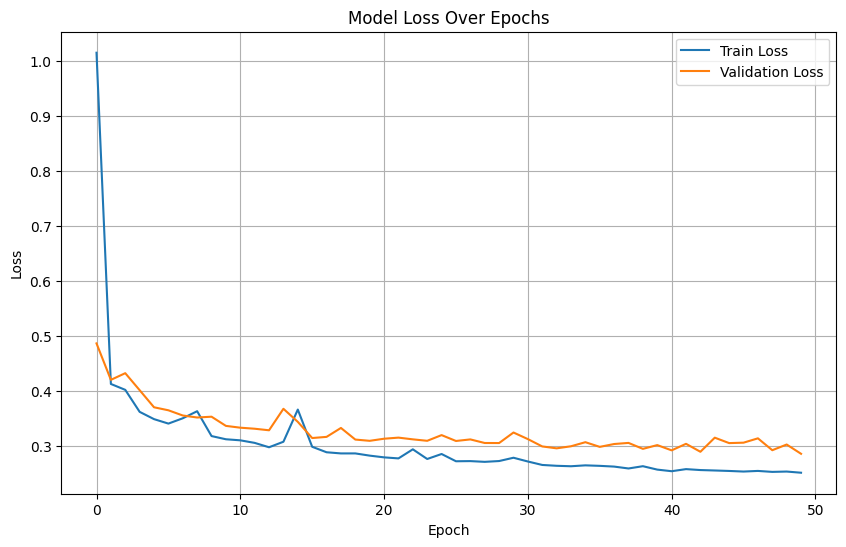

In [ ]:
history = model.fit(X_train_scaled, y_train, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# Plot training history
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### 8. Predict house prices

In [ ]:
y_pred = model.predict(X_test_scaled)

print("First 5 predictions:", y_pred[:5].flatten())
print("First 5 actual values:", y_test[:5].values)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
First 5 predictions: [0.52120036 0.98666537 4.959085   2.5240676  3.0782883 ]
First 5 actual values: [0.477   0.458   5.00001 2.186   2.78   ]


### 9. Evaluate using MSE, MAE, RMSE

Mean Squared Error (MSE): 0.2819
Mean Absolute Error (MAE): 0.3629
Root Mean Squared Error (RMSE): 0.5310


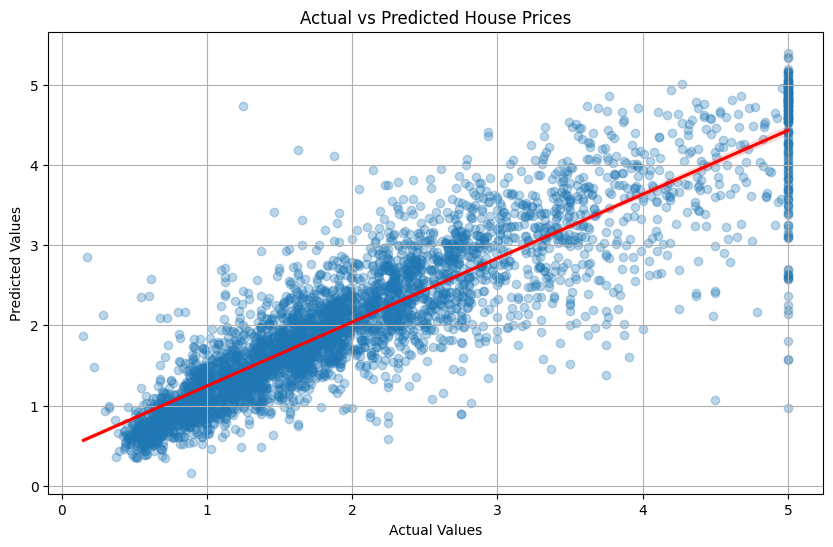

In [ ]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

# Visualize predictions vs actual values
plt.figure(figsize=(10, 6))
sns.regplot(x=y_test, y=y_pred.flatten(), scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted House Prices')
plt.grid(True)
plt.show()

In [2]:
data_path="/content/data (2).csv"

## Breast Cancer Wisconsin Dataset

**Source**: Scikit-learn

**Description**:
* Samples: 569
* Features: 30
* Classes:
    * Malignant
    * Benign

**Algorithm Steps**:
1. Import libraries.
2. Load Breast Cancer dataset.
3. Split dataset.
4. Standardize features.
5. Design ANN.
6. Compile model.
7. Train model.
8. Predict labels.
9. Evaluate using: Accuracy, Precision, Recall, F1-score, Confusion Matrix.

### 1. Import libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

### 2. Load Breast Cancer dataset

In [4]:
cancer = load_breast_cancer()
X_bc = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_bc = pd.Series(cancer.target)

print("Features (X_bc) shape:", X_bc.shape)
print("Target (y_bc) shape:", y_bc.shape)
display(X_bc.head())
print(cancer.target_names)

Features (X_bc) shape: (569, 30)
Target (y_bc) shape: (569,)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


['malignant' 'benign']


### 3. Split dataset

In [5]:
X_train_bc, X_test_bc, y_train_bc, y_test_bc = train_test_split(X_bc, y_bc, test_size=0.2, random_state=42, stratify=y_bc)

print("X_train_bc shape:", X_train_bc.shape)
print("X_test_bc shape:", X_test_bc.shape)
print("y_train_bc shape:", y_train_bc.shape)
print("y_test_bc shape:", y_test_bc.shape)

X_train_bc shape: (455, 30)
X_test_bc shape: (114, 30)
y_train_bc shape: (455,)
y_test_bc shape: (114,)


### 4. Standardize features

In [6]:
scaler_bc = StandardScaler()
X_train_scaled_bc = scaler_bc.fit_transform(X_train_bc)
X_test_scaled_bc = scaler_bc.transform(X_test_bc)

print("X_train_scaled_bc shape:", X_train_scaled_bc.shape)
print("X_test_scaled_bc shape:", X_test_scaled_bc.shape)

X_train_scaled_bc shape: (455, 30)
X_test_scaled_bc shape: (114, 30)


### 5. Design ANN

In [7]:
model_bc = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled_bc.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid') # Output layer for binary classification
])

model_bc.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

### 6. Compile model

In [8]:
model_bc.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

### 7. Train model

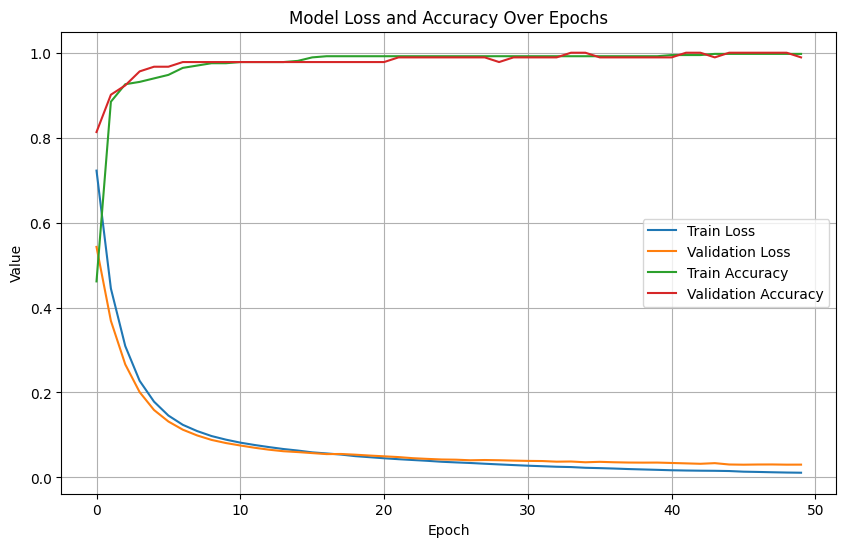

In [9]:
history_bc = model_bc.fit(X_train_scaled_bc, y_train_bc, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# Plot training history
plt.figure(figsize=(10, 6))
plt.plot(history_bc.history['loss'], label='Train Loss')
plt.plot(history_bc.history['val_loss'], label='Validation Loss')
plt.plot(history_bc.history['accuracy'], label='Train Accuracy')
plt.plot(history_bc.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Loss and Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.show()

### 8. Predict labels

In [10]:
y_pred_probs_bc = model_bc.predict(X_test_scaled_bc)
y_pred_bc = (y_pred_probs_bc > 0.5).astype(int).flatten()

print("First 5 predicted probabilities:", y_pred_probs_bc[:5].flatten())
print("First 5 predicted labels:", y_pred_bc[:5])
print("First 5 actual labels:", y_test_bc[:5].values)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
First 5 predicted probabilities: [4.7644202e-12 9.9999964e-01 5.6518249e-05 3.5730645e-02 1.6692006e-14]
First 5 predicted labels: [0 1 0 0 0]
First 5 actual labels: [0 1 0 1 0]


### 9. Evaluate model

Accuracy: 0.9649
Precision: 0.9857
Recall: 0.9583
F1-Score: 0.9718


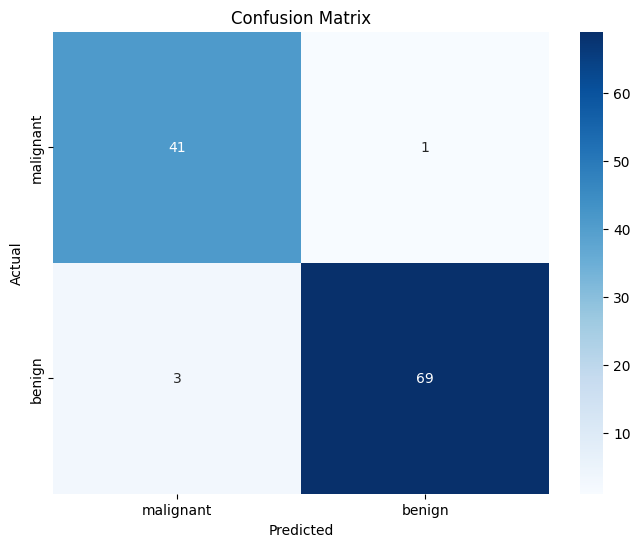

In [11]:
accuracy = accuracy_score(y_test_bc, y_pred_bc)
precision = precision_score(y_test_bc, y_pred_bc)
recall = recall_score(y_test_bc, y_pred_bc)
f1 = f1_score(y_test_bc, y_pred_bc)
conf_matrix = confusion_matrix(y_test_bc, y_pred_bc)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=cancer.target_names, yticklabels=cancer.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()